# Fourier basis — figures

The figures of Supplementary Note 1, made **only from saved results**: numpy
and matplotlib, no `curlew` or `torch`.

| file | written by | contents |
|---|---|---|
| `direction_seeds.npz` | `s01a_fourier_basis_directions` | largest gap and angle to a fixed axis for every method, $R$ and seed; one set of rays per method for the nets |
| `energy_bias.npz` | `s01c_fourier_basis_energy_bias` | each basis trained two ways, per seed and band: loss, $\sum a_i^2$ and strain energy against iteration, scores, final amplitudes per mode; contacts of the main-text seed |
| `band_sweep.npz` | `s01b_fourier_basis_sweeps` | recumbent-fold fits over a grid of wavelength bands: scores, interior extrema, displacement per octave, contacts |

Figures are written to `figures/`: `figS_fourier_basis_band`,
`figS_fourier_basis_directions` and `figS_fourier_basis_energy`.


In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

import sys
sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle, diagnostics
import figstyle
import diagnostics
figstyle.apply()

RES_DIR = Path("./results")
FIG_DIR = Path("./figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

## Load

In [2]:
res = np.load(RES_DIR / "direction_seeds.npz")
R_VALUES = tuple(int(r) for r in res["r_values"])
R_NET = int(res["net_r"])
METHODS = ("Sobol'", "Fibonacci", "independent")
KEY = {"Sobol'": "sobol", "Fibonacci": "fibonacci", "independent": "independent"}
gap = {(m, R): res[f"gap_{KEY[m]}_{R}"] for m in METHODS for R in R_VALUES}
target = {(m, R): res[f"target_{KEY[m]}_{R}"] for m in METHODS for R in R_VALUES}
net = {"Sobol'": res["net_sobol"], "Fibonacci": res["net_fibonacci"]}

COLORS = {
    "Sobol'": figstyle.HORIZON_PALETTE[4],
    "Fibonacci": figstyle.HORIZON_PALETTE[0],
    "independent": "0.45",
}
LABELS = {"Sobol'": "Sobol'", "Fibonacci": "rotated Fibonacci", "independent": "independent"}

## Nets

The colour is the angle from each axis to its nearest ray, so dark is covered
and bright is a gap. The white ring is the largest empty cap; a cap that
crosses the primitive circle reappears on the opposite side of the net.

In [3]:
NET_N = 501
xx, yy, rr, nn = diagnostics._schmidt_grid(NET_N)
inside = rr <= 1.0
TEST = nn[inside]


def nearest_angle(points, axes):
    best = np.abs(points @ axes.T).max(axis=1)
    return np.degrees(np.arccos(np.clip(best, -1.0, 1.0)))


def small_circle(centre, radius_deg, n=361):
    # Points on the cone of half-angle `radius_deg` about `centre`.
    c = centre / np.linalg.norm(centre)
    a = np.cross(c, [0.0, 0.0, 1.0] if abs(c[2]) < 0.9 else [1.0, 0.0, 0.0])
    a /= np.linalg.norm(a)
    b = np.cross(c, a)
    t = np.linspace(0.0, 2.0 * np.pi, n)
    r = np.radians(radius_deg)
    return np.cos(r) * c + np.sin(r) * (np.outer(np.cos(t), a) + np.outer(np.sin(t), b))


def draw_net(ax, axes, color, norm, title):
    near = np.full(xx.shape, np.nan)
    near[inside] = nearest_angle(TEST, axes)
    m = ax.pcolormesh(xx, yy, near, cmap=figstyle.ramp(), norm=norm,
                      shading="auto", rasterized=True)
    diagnostics._draw_schmidt_net(ax)
    k = int(np.nanargmax(near[inside]))
    ring = diagnostics._schmidt_xy(small_circle(TEST[k], near[inside][k]))
    jump = np.r_[False, np.linalg.norm(np.diff(ring, axis=0), axis=1) > 0.3]
    for seg in np.split(ring, np.nonzero(jump)[0]):
        ax.plot(seg[:, 0], seg[:, 1], color="white", lw=1.1, zorder=6)
    pts = diagnostics._schmidt_xy(axes)
    ax.scatter(pts[:, 0], pts[:, 1], s=12, color=color, edgecolors="white",
               linewidths=0.5, zorder=7)
    ax.set_title(f"{title}, R = {R_NET} (gap {np.nanmax(near):.0f}°)")
    return m


def seed_strip(ax, data, ylabel):
    rng = np.random.default_rng(0)
    width = 0.26
    for i, R in enumerate(R_VALUES):
        for j, m in enumerate(METHODS):
            x0 = i + (j - 1) * width
            v = data[(m, R)]
            ax.scatter(x0 + rng.uniform(-0.07, 0.07, len(v)), v, s=3,
                       color=COLORS[m], alpha=0.3, lw=0)
            p5, p50, p95 = np.percentile(v, [5, 50, 95])
            ax.errorbar(x0, p50, yerr=[[p50 - p5], [p95 - p50]], fmt="o",
                        color=COLORS[m], ms=3.5, lw=1.0, capsize=2,
                        label=LABELS[m] if i == 0 else None)
    ax.set_xticks(range(len(R_VALUES)), [f"R = {R}" for R in R_VALUES])
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, None)

## Fig. S2: the ray directions

**a** Sobol' and **b** the rotated Fibonacci set, one set of $R = 32$ rays
each. **c** The largest gap over 200 seeds for each $R$. Points are seeds,
markers the median, bars the 5th to 95th percentiles. One row, at print width.


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


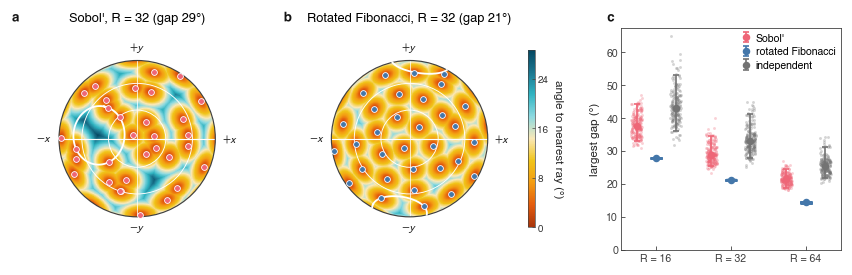

In [4]:
# Inches at print size, one row: net a, net b, colour bar, strip c.
# Net boxes are square, so the equal-aspect adjustment does not move them.
fig_w = figstyle.PRINT_WIDTH
pad_l, net_gap, cbar_pad, cbar_w, strip_gap, right = 0.22, 0.42, 0.06, 0.06, 0.72, 0.08
side = 1.85
strip_w = fig_w - pad_l - 2 * side - net_gap - cbar_pad - cbar_w - strip_gap - right
top, bottom = 0.26, 0.40
fig_h = top + side + bottom


def inches(x0, y0, w, h):
    return [x0 / fig_w, y0 / fig_h, w / fig_w, h / fig_h]


norm = Normalize(0.0, max(nearest_angle(TEST, a).max() for a in net.values()))
fig = figstyle.print_figure(height=fig_h)
x_a = pad_l
x_b = x_a + side + net_gap
ax_a = fig.add_axes(inches(x_a, bottom, side, side))
draw_net(ax_a, net["Sobol'"], COLORS["Sobol'"], norm, "Sobol'")
ax_b = fig.add_axes(inches(x_b, bottom, side, side))
m = draw_net(ax_b, net["Fibonacci"], COLORS["Fibonacci"], norm, "Rotated Fibonacci")
cax = fig.add_axes(inches(x_b + side + cbar_pad, bottom + 0.1 * side, cbar_w, 0.8 * side))
figstyle.add_cbar(cax, m, "angle to nearest ray (°)")

x_c = x_b + side + cbar_pad + cbar_w + strip_gap
ax_c = fig.add_axes(inches(x_c, bottom, strip_w, side))
seed_strip(ax_c, gap, "largest gap (°)")
ax_c.legend(loc="upper right", handletextpad=0.2, borderaxespad=0.2)

for ax, letter in zip((ax_a, ax_b, ax_c), "abc"):
    figstyle.panel_label(ax, letter)

figstyle.save(fig, FIG_DIR / "figS_fourier_basis_directions")
plt.show()


## Numbers quoted in Supplementary Note 1

In [5]:
for R in R_VALUES:
    for m in METHODS:
        g, t = gap[(m, R)], target[(m, R)]
        print(f"R={R:>2} {m:>12}: largest gap {np.median(g):.1f} deg "
              f"(5-95%: {np.percentile(g, 5):.1f}-{np.percentile(g, 95):.1f}, max {g.max():.1f}, "
              f"spread {np.ptp(g):.2f}); fixed axis 95th pct {np.percentile(t, 95):.1f}, "
              f"max {t.max():.1f} deg")

R=16       Sobol': largest gap 37.6 deg (5-95%: 32.9-44.3, max 47.0, spread 16.24); fixed axis 95th pct 28.5, max 37.9 deg
R=16    Fibonacci: largest gap 27.8 deg (5-95%: 27.8-27.9, max 27.9, spread 0.18); fixed axis 95th pct 22.5, max 25.4 deg
R=16  independent: largest gap 43.0 deg (5-95%: 36.1-52.9, max 64.9, spread 33.17); fixed axis 95th pct 33.0, max 46.2 deg
R=32       Sobol': largest gap 28.6 deg (5-95%: 25.4-34.6, max 39.9, spread 16.80); fixed axis 95th pct 19.7, max 25.6 deg
R=32    Fibonacci: largest gap 21.2 deg (5-95%: 21.2-21.3, max 21.3, spread 0.20); fixed axis 95th pct 15.5, max 18.6 deg
R=32  independent: largest gap 32.9 deg (5-95%: 27.8-41.1, max 44.9, spread 19.87); fixed axis 95th pct 25.0, max 33.1 deg
R=64       Sobol': largest gap 21.4 deg (5-95%: 18.8-24.5, max 27.1, spread 9.01); fixed axis 95th pct 15.0, max 20.0 deg
R=64    Fibonacci: largest gap 14.3 deg (5-95%: 14.3-14.4, max 14.4, spread 0.31); fixed axis 95th pct 11.2, max 14.2 deg
R=64  independent: l

## Sweeps: load and shared drawing

Truth contacts from `01_recumbent_fold/data/synthetic/truth.npz`, in the
fits' frame. Each section shows every seed's contacts over the true ones
(dashed), with the fitted data (contact points and bedding with younging).

In [6]:
FOLD_DATA = Path("../01_recumbent_fold/data")
band = np.load(RES_DIR / "band_sweep.npz")
truth = np.load(FOLD_DATA / "synthetic/truth.npz")
inputs = np.load("../01_recumbent_fold/results/synthetic/inputs.npz")
origin = inputs["origin"]
# The fitted data, in the fits' frame: contact points per horizon and bedding with younging.
data_horizons = [inputs[f"horizon_{h}"] for h in range(2)]
data_gp, data_gv = inputs["gp"], inputs["gv"]
truth_contacts = [truth[f"contact_{name}"] - origin for name in ("rock2", "rock1")]   # H0, H1
H_COLORS = [figstyle.HORIZON_PALETTE[0], figstyle.HORIZON_PALETTE[1]]
N_SEEDS = len(band["seeds"])
HALF = 600.0
DATA_KW = dict(colors={f"H{h}": c for h, c in enumerate(H_COLORS)}, scatter_s=9, quiver_scale=0.013)


def draw_data(ax):
    figstyle.overlay_constraints(ax, data_horizons, [f"H{h}" for h in range(2)], data_gp, data_gv, **DATA_KW)


OUTSIDE_GREY = "0.86"      # opaque: transparent fills render unevenly across PDF viewers


def tint(color, f):
    # Opaque mix of `color` with white, f in [0, 1].
    from matplotlib.colors import to_rgb
    return tuple(1.0 - f * (1.0 - np.asarray(to_rgb(color))))


def setting_contacts(res, k):
    # Contacts of every seed of setting k: [seed][horizon] -> [polyline, ...].
    n_set = res["loss"].shape[0]
    flat = diagnostics.unpack_contacts(res, n_set * N_SEEDS, 2)
    return flat[k * N_SEEDS:(k + 1) * N_SEEDS]


def draw_section(ax, res, k, title, *, xlabel=False, ylabel=False):
    for member in setting_contacts(res, k):
        for h, lines in enumerate(member):
            for line in lines:
                ax.plot(line[:, 0], line[:, 1], color=H_COLORS[h], lw=0.6, alpha=0.8, zorder=2)
    for line in truth_contacts:
        ax.plot(line[:, 0], line[:, 1], color="0.1", lw=0.8, ls=(0, (3, 2)), zorder=3)
    draw_data(ax)
    ext = int(res["extrema"][k].max())
    ax.set_xlim(-HALF, HALF)
    ax.set_ylim(-HALF, HALF)
    ax.set_aspect("equal")
    ax.set_title(title + ("" if ext == 0 else f" ({ext} extrema)"))
    ax.set_xticks([-500, 0, 500])
    ax.set_yticks([-500, 0, 500])
    ax.set_xlabel("x (m)" if xlabel else "")
    ax.set_ylabel("z (m)" if ylabel else "")
    if not xlabel:
        ax.set_xticklabels([])
    if not ylabel:
        ax.set_yticklabels([])


def score(res):
    # Per setting: median over seeds of the mean contact distance and the mean IoU.
    cd = np.median(res["contact_distance"].mean(axis=2), axis=1)
    iou = np.median(res["iou"].mean(axis=2), axis=1)
    return cd, iou


def km(v):
    return f"{v / 1000:g}"


def inches(fig_w, fig_h, x0, y0, w, h):
    return [x0 / fig_w, y0 / fig_h, w / fig_w, h / fig_h]

## Fig. S1: the wavelength band

**a** Median contact distance and **b** median IoU over the seeds, for each
band; the main-text band is outlined. Grey cells have $L_{\min} \ge L_{\max}$.
**c–e** Every seed's contacts for three bands, over the true contacts
(dashed), with the fitted data.

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array


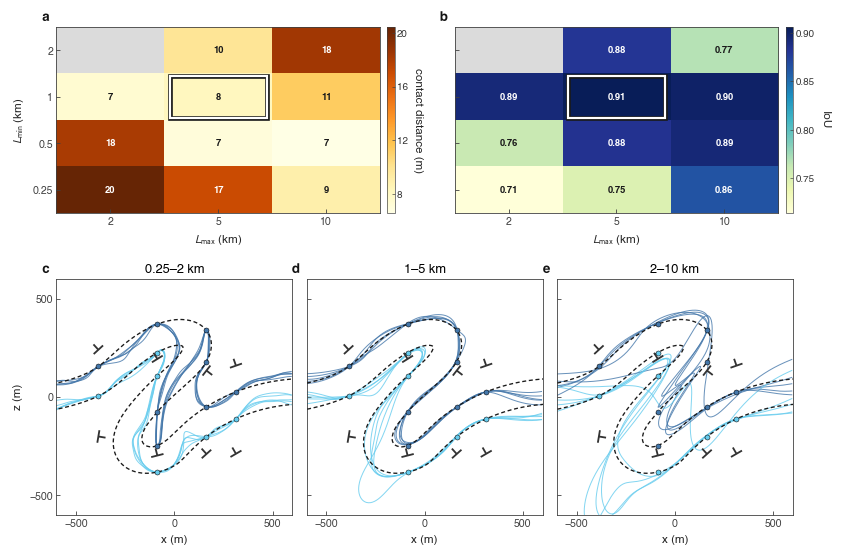

In [10]:
bands = band["bands"]
L_MIN = np.unique(bands[:, 0])
L_MAX = np.unique(bands[:, 1])
cd, iou = score(band)
MAIN = (1000.0, 5000.0)
SHOW = [(250.0, 2000.0), MAIN, (2000.0, 10000.0)]


def band_table(ax, values, cmap, fmt, label, cax, *, ylabel=True):
    grid = np.full((len(L_MIN), len(L_MAX)), np.nan)
    for (lo, hi), v in zip(bands, values):
        grid[np.searchsorted(L_MIN, lo), np.searchsorted(L_MAX, hi)] = v
    cmap = cmap.with_extremes(bad=OUTSIDE_GREY)                       # blank cells: no band
    m = ax.imshow(np.ma.masked_invalid(grid), cmap=cmap, origin="lower", aspect="auto")
    for i in range(len(L_MIN)):
        for j in range(len(L_MAX)):
            if np.isfinite(grid[i, j]):
                r, g, b_, _ = m.cmap(m.norm(grid[i, j]))
                dark = 0.299 * r + 0.587 * g + 0.114 * b_ < 0.5            # white text on dark cells
                ax.text(j, i, fmt(grid[i, j]), ha="center", va="center", color="white" if dark else "0.1",
                        fontsize=figstyle.pt(8), fontweight="bold")
    i, j = np.searchsorted(L_MIN, MAIN[0]), np.searchsorted(L_MAX, MAIN[1])
    # White outline with a dark halo: visible on the darkest and the lightest cells.
    from matplotlib import patheffects
    ax.add_patch(plt.Rectangle((j - 0.45, i - 0.45), 0.9, 0.9, fill=False, ec="white", lw=1.3,
                               path_effects=[patheffects.withStroke(linewidth=2.8, foreground="0.1")]))
    ax.set_xticks(range(len(L_MAX)), [km(v) for v in L_MAX])
    ax.set_yticks(range(len(L_MIN)), [km(v) for v in L_MIN] if ylabel else [])
    ax.set_xlabel(r"$L_{\max}$ (km)")
    ax.set_ylabel(r"$L_{\min}$ (km)" if ylabel else "")
    figstyle.add_cbar(cax, m, label)


fig_w = figstyle.PRINT_WIDTH
left, gap_w, cbar_pad, cbar_w, right = 0.50, 0.50, 0.06, 0.06, 0.45   # b shares a's y axis
table_w = (fig_w - left - 2 * (cbar_pad + cbar_w) - gap_w - right) / 2.0
table_h = 1.55
sec_gap = 0.12
sec_w = (fig_w - left - right - 2 * sec_gap) / 3.0
top, row_gap, bottom = 0.26, 0.55, 0.40
fig_h = top + table_h + row_gap + sec_w + bottom
y_tab = bottom + sec_w + row_gap
fig = figstyle.print_figure(height=fig_h)
P_ = lambda *a: inches(fig_w, fig_h, *a)

ax_a = fig.add_axes(P_(left, y_tab, table_w, table_h))
cax_a = fig.add_axes(P_(left + table_w + cbar_pad, y_tab, cbar_w, table_h))
# Two sequential maps, darker for more: distance (lower is better) and IoU (higher is better).
band_table(ax_a, cd, plt.get_cmap("YlOrBr"), lambda v: f"{v:.0f}", "contact distance (m)", cax_a)
x_b = left + table_w + cbar_pad + cbar_w + gap_w
ax_b = fig.add_axes(P_(x_b, y_tab, table_w, table_h))
cax_b = fig.add_axes(P_(x_b + table_w + cbar_pad, y_tab, cbar_w, table_h))
band_table(ax_b, iou, plt.get_cmap("YlGnBu"), lambda v: f"{v:.2f}", "IoU", cax_b, ylabel=False)

sections = []
for n, b in enumerate(SHOW):
    k = int(np.nonzero((bands[:, 0] == b[0]) & (bands[:, 1] == b[1]))[0][0])
    ax = fig.add_axes(P_(left + n * (sec_w + sec_gap), bottom, sec_w, sec_w))
    draw_section(ax, band, k, f"{km(b[0])}–{km(b[1])} km", xlabel=True, ylabel=n == 0)
    sections.append(ax)

for ax, letter in zip([ax_a, ax_b, *sections], "abcde"):
    figstyle.panel_label(ax, letter)
figstyle.save(fig, FIG_DIR / "figS_fourier_basis_band")
plt.show()

## Sweep numbers quoted in Supplementary Note 1

In [8]:
for label, res, keys in (("band", band, [f"{km(lo)}-{km(hi)} km" for lo, hi in band["bands"]]),):
    cd, iou = score(res)
    print(label)
    for k, key in enumerate(keys):
        c = np.median(res["contact_distance"][k], axis=0)
        print(f"  {key:>14}: contact distance {cd[k]:5.1f} m (H0 {c[0]:.1f}, H1 {c[1]:.1f}), "
              f"IoU {iou[k]:.2f}, extrema max {int(res['extrema'][k].max())}, "
              f"loss median {np.median(res['loss'][k]):.3g}")

band
       0.25-2 km: contact distance  20.5 m (H0 21.2, H1 19.3), IoU 0.71, extrema max 0, loss median 2.38e-07
       0.25-5 km: contact distance  17.0 m (H0 16.2, H1 17.0), IoU 0.75, extrema max 0, loss median 8.82e-07
      0.25-10 km: contact distance   9.0 m (H0 6.3, H1 10.8), IoU 0.86, extrema max 0, loss median 1.33e-10
        0.5-2 km: contact distance  18.2 m (H0 16.2, H1 20.0), IoU 0.76, extrema max 0, loss median 4.56e-08
        0.5-5 km: contact distance   7.0 m (H0 6.8, H1 7.2), IoU 0.88, extrema max 0, loss median 2.83e-09
       0.5-10 km: contact distance   6.6 m (H0 5.5, H1 8.1), IoU 0.89, extrema max 0, loss median 3.27e-07
          1-2 km: contact distance   7.4 m (H0 7.4, H1 7.6), IoU 0.89, extrema max 0, loss median 1.01e-08
          1-5 km: contact distance   8.2 m (H0 5.4, H1 10.9), IoU 0.91, extrema max 0, loss median 2.96e-05
         1-10 km: contact distance  11.3 m (H0 6.4, H1 17.1), IoU 0.90, extrema max 0, loss median 0.000213
          2-5 km: conta

## Fig. S3: energy-biased training

Each basis trained two ways (`s01c`), compared within each seed, for the
main-text band and the wider band: one colour per training and band, and in
**c, d, f** circles for the main-text band and triangles for the wider one. **a**
$\sum_i a_i^2$ and **b** strain energy of the map against iteration: the median
over the bases, with the interquartile range shaded. **c** Strain energy and **d** the IoU of each of the
three units, one point per seed (and unit), ours at the end against Adam at
the same loss (its first iteration at or below ours' final loss); above the
diagonal (red) Adam is higher, below it (blue) ours is. **e** Loss against
iteration; dotted, the fit threshold. **f** Where the amplitude goes: $\sum a_i^2$ per octave of wavelength,
the median over the bases, ours at the end and Adam at the same loss. **g, h** Contacts of the main-text seed's two fits
(main band), ours at the end and Adam at the same loss, over the true contacts
(dashed), with the fitted data. A basis is left out of a band if
either of its trainings did not fit the data (final loss above `FIT_LOSS`).

left out (main): ours on seed 820551442 (final loss 0.0011)
left out (main): adam on seed 1766903757 (final loss 1.3)
main band 1–5 km: paired comparisons on 13 of 15 bases
left out (wide): adam on seed 1237445433 (final loss 2.4)
left out (wide): adam on seed 1766903757 (final loss 2.9)
wide band 0.25–5 km: paired comparisons on 13 of 15 bases


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


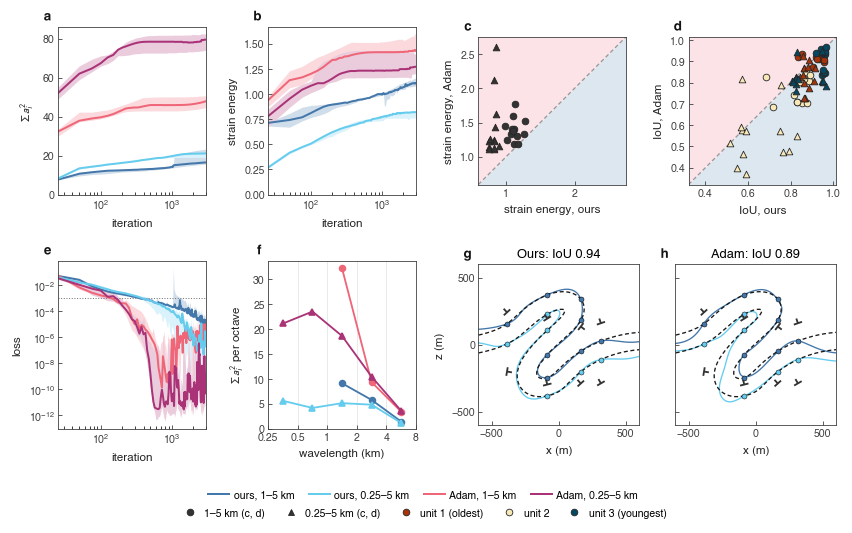


main band 1–5 km, 13 bases:
  Adam reaches ours' final loss at iteration median 331 (range 141-644; -1 = never)
  Adam at ours' loss: loss median 2e-05 (ours 2e-05)
    strain: ours 1.107, Adam 1.372, Adam/ours median 1.24, ours lower in 13/13
    sum_a2: ours 16.511, Adam 45.321, Adam/ours median 2.74, ours lower in 12/13
    strain_p90: ours 3.266, Adam 3.413, Adam/ours median 1.16, ours lower in 9/13
    IoU unit 1: ours 0.934, Adam 0.918, ours higher in 10/13
    IoU unit 2: ours 0.842, Adam 0.801, ours higher in 12/13
    IoU unit 3: ours 0.953, Adam 0.940, ours higher in 11/13
  Adam final: loss median 1.5e-06 (ours 2e-05)
    strain: ours 1.107, Adam 1.432, Adam/ours median 1.32, ours lower in 13/13
    sum_a2: ours 16.511, Adam 47.907, Adam/ours median 2.93, ours lower in 12/13
    strain_p90: ours 3.266, Adam 3.795, Adam/ours median 1.21, ours lower in 10/13
    IoU unit 1: ours 0.934, Adam 0.907, ours higher in 8/13
    IoU unit 2: ours 0.842, Adam 0.815, ours higher in 10/1

In [9]:
eb = np.load(RES_DIR / "energy_bias.npz")
VARIANTS = [str(v) for v in eb["variants"]]
BANDS = [str(b) for b in eb["bands"]]
B_RANGE = {b: tuple(r) for b, r in zip(BANDS, eb["band_ranges"])}
V_LABEL = {"ours": "ours", "adam": "Adam"}
V_COLOR = {"ours": figstyle.HORIZON_PALETTE[0], "adam": figstyle.HORIZON_PALETTE[4]}
# One colour per training and band (the band's darker or lighter shade of the training's hue);
# in c, d and f the marker is the band.
C_LINE = {("ours", "main"): figstyle.HORIZON_PALETTE[0], ("ours", "wide"): figstyle.HORIZON_PALETTE[1],
          ("adam", "main"): figstyle.HORIZON_PALETTE[4], ("adam", "wide"): figstyle.HORIZON_PALETTE[5]}
B_MARKER = {"main": "o", "wide": "^"}
B_LABEL = {b: f"{B_RANGE[b][0] / 1000:g}–{B_RANGE[b][1] / 1000:g} km" for b in BANDS}
eb_contacts = diagnostics.unpack_contacts(eb, len(VARIANTS) + 1, 2)   # ours, Adam final, Adam at ours' loss
n_seeds = len(eb["seeds"])
it_all = eb[f"{BANDS[0]}_ours_iteration"][0]


def get(b, v, key):
    return eb[f"{b}_{v}_{key}"]


# A training has fitted the data if its final loss is below FIT_LOSS. Within a band, a basis is
# kept only if both of its trainings fit, so every comparison is between the same bases.
FIT_LOSS = 1e-3
paired_ok = {}
for b in BANDS:
    fitted = {v: get(b, v, "loss")[:, -1] < FIT_LOSS for v in VARIANTS}
    paired_ok[b] = np.logical_and.reduce([fitted[v] for v in VARIANTS])
    for v in VARIANTS:
        for k in np.nonzero(~fitted[v])[0]:
            print(f"left out ({b}): {v} on seed {eb['seeds'][k]} (final loss {get(b, v, 'loss')[k, -1]:.2g})")
    print(f"{b} band {B_LABEL[b]}: paired comparisons on {paired_ok[b].sum()} of {n_seeds} bases")


def draw_fit(ax, contacts, title, *, ylabel=False):
    for h, lines in enumerate(contacts):
        for line in lines:
            ax.plot(line[:, 0], line[:, 1], color=H_COLORS[h], lw=0.8, zorder=2)
    for line in truth_contacts:
        ax.plot(line[:, 0], line[:, 1], color="0.1", lw=0.8, ls=(0, (3, 2)), zorder=3)
    draw_data(ax)
    ax.set_xlim(-HALF, HALF)
    ax.set_ylim(-HALF, HALF)
    ax.set_aspect("equal")
    ax.set_title(title)
    ax.set_xticks([-500, 0, 500])
    ax.set_yticks([-500, 0, 500])
    ax.set_xlabel("x (m)")
    ax.set_ylabel("z (m)" if ylabel else "")
    if not ylabel:
        ax.set_yticklabels([])


def paired(ax, key, label, *, series=None):
    # One point per basis (and per series column): ours at the end on x, Adam at ours' final loss
    # on y. Above the diagonal, Adam is higher. Marker shape is the band.
    # `series`: list of (column, colour, label) when each basis has several values.
    pts = {}
    for b in BANDS:
        x = get(b, "ours", key)[paired_ok[b]]
        y = get(b, "adam_matched", key)[paired_ok[b]]
        if x.ndim > y.ndim:                          # logged against iteration: ours' final state
            x = x[:, -1]
        pts[b] = (x, y)
    allv = np.concatenate([np.ravel(a) for xy in pts.values() for a in xy])
    lo, hi = allv.min(), allv.max()
    pad = 0.08 * (hi - lo)
    lo, hi = lo - pad, hi + pad
    ax.fill_between([lo, hi], [lo, hi], hi, color=tint(V_COLOR["adam"], 0.18), lw=0, zorder=0)
    ax.fill_between([lo, hi], lo, [lo, hi], color=tint(V_COLOR["ours"], 0.18), lw=0, zorder=0)
    ax.plot([lo, hi], [lo, hi], color="0.6", lw=0.8, ls=(0, (3, 2)), zorder=1)
    cols = series if series is not None else [(None, "0.2", None)]
    for b in BANDS:
        x, y = pts[b]
        for col, color, _ in cols:
            xs, ys = (x, y) if col is None else (x[:, col], y[:, col])
            ax.scatter(xs, ys, s=16, marker=B_MARKER[b], facecolors=color, edgecolors="0.15",
                       linewidths=0.5, zorder=3)
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_aspect("equal")
    ax.set_xlabel(f"{label}, ours")
    ax.set_ylabel(f"{label}, Adam")


def envelope(ax, b, v, key, *, log=False):
    # Median over the bases, with the interquartile range shaded.
    it = get(b, v, "iteration")[0]
    y = get(b, v, key)[paired_ok[b]]
    keep = it > 0                                    # the iteration axis is logarithmic
    it, y = it[keep], y[:, keep]
    lo, mid, hi = (np.exp(np.percentile(np.log(y), q, axis=0)) for q in (25, 50, 75)) if log else \
        (np.percentile(y, q, axis=0) for q in (25, 50, 75))
    ax.fill_between(it, lo, hi, color=tint(C_LINE[(v, b)], 0.25), lw=0, zorder=0)
    ax.plot(it, mid, color=C_LINE[(v, b)], lw=1.2)


OCTAVES = 250.0 * 2.0 ** np.arange(0, 6)          # wavelength bin edges (m), one octave each


COMPARED = {"ours": "ours", "adam": "adam_matched"}  # the states compared: ours at the end, Adam at ours' loss


def octave_energy(b, v):
    # sum a_i^2 per octave of wavelength, per basis; median over the bases.
    amp, wl = get(b, v, "amplitude")[paired_ok[b]], get(b, v, "wavelength")[paired_ok[b]]
    idx = np.digitize(wl, OCTAVES) - 1
    out = np.zeros((len(amp), len(OCTAVES) - 1))
    for s_ in range(len(amp)):
        np.add.at(out[s_], np.clip(idx[s_], 0, len(OCTAVES) - 2), amp[s_] ** 2)
    present = np.any(idx == np.arange(len(OCTAVES) - 1)[:, None, None], axis=(1, 2))   # bins the band covers
    return np.sqrt(OCTAVES[:-1] * OCTAVES[1:])[present], np.median(out, axis=0)[present]


fig_w = figstyle.PRINT_WIDTH
left, right, gap_w = 0.50, 0.10, 0.52
plot_w = (fig_w - left - right - 3 * gap_w) / 4.0
plot_h = 1.40
sec_gap = 0.30                              # room for panel h's letter
sec_w = (fig_w - left - right - 2 * (plot_w + gap_w) - sec_gap) / 2.0
top, row_gap, bottom = 0.26, 0.55, 0.86    # bottom: x labels and the key
fig_h = top + plot_h + row_gap + plot_h + bottom
y_top = bottom + plot_h + row_gap
fig = figstyle.print_figure(height=fig_h)
P_ = lambda *a: inches(fig_w, fig_h, *a)
tops = [fig.add_axes(P_(left + k * (plot_w + gap_w), y_top, plot_w, plot_h)) for k in range(4)]
ax_a, ax_b, ax_c, ax_d = tops
ax_e = fig.add_axes(P_(left, bottom, plot_w, plot_h))
ax_f = fig.add_axes(P_(left + plot_w + gap_w, bottom, plot_w, plot_h))

for b in BANDS:
    for v in VARIANTS:
        envelope(ax_a, b, v, "sum_a2")
        envelope(ax_b, b, v, "strain")
        envelope(ax_e, b, v, "loss", log=True)
        x, y = octave_energy(b, COMPARED[v])
        ax_f.plot(x, y, marker=B_MARKER[b], color=C_LINE[(v, b)], lw=1.1, ms=3.5)
ax_a.set_ylabel(r"$\Sigma\,a_i^2$")
ax_a.set_ylim(0, None)
ax_b.set_ylabel("strain energy")
ax_b.set_ylim(0, None)
ax_e.set_yscale("log")
ax_e.set_ylabel("loss")
ax_e.axhline(FIT_LOSS, color="0.45", lw=0.6, ls=":", zorder=1)    # FIT_LOSS
for ax in (ax_a, ax_b, ax_e):
    ax.set_xscale("log")
    ax.set_xlim(it_all[1], it_all[-1])
    ax.set_xlabel("iteration")
ax_f.set_xscale("log")
ax_f.set_xlim(OCTAVES[0], OCTAVES[-1])
ax_f.set_xticks(OCTAVES, [km(v) for v in OCTAVES])
ax_f.minorticks_off()
ax_f.grid(axis="x", color="0.9", lw=0.5, zorder=0)    # octave edges
ax_f.set_xlabel("wavelength (km)")
ax_f.set_ylabel(r"$\Sigma\,a_i^2$ per octave")
ax_f.set_ylim(0, None)

paired(ax_c, "strain", "strain energy")
unit_cmap, unit_norm = figstyle.litho_cmap([1, 2, 3])      # the lithology colours of the main figures
UNITS = [(0, unit_cmap(unit_norm(1)), "unit 1 (oldest)"), (1, unit_cmap(unit_norm(2)), "unit 2"),
         (2, unit_cmap(unit_norm(3)), "unit 3 (youngest)")]
paired(ax_d, "iou", "IoU", series=UNITS)

sections = []
for k, (name, member, title) in enumerate((("ours", 0, "Ours"), ("adam_matched", 2, "Adam"))):
    x0 = left + 2 * (plot_w + gap_w) + k * (sec_w + sec_gap)
    ax = fig.add_axes(P_(x0, bottom + 0.5 * (plot_h - sec_w), sec_w, sec_w))
    iou = get("main", name, "iou")[0].mean()
    draw_fit(ax, eb_contacts[member], f"{title}: IoU {iou:.2f}", ylabel=k == 0)
    sections.append(ax)

from matplotlib.lines import Line2D
lines_key = [Line2D([], [], color=C_LINE[(v, b)], lw=1.2, label=f"{V_LABEL[v]}, {B_LABEL[b]}")
             for v in VARIANTS for b in BANDS]
markers_key = [Line2D([], [], ls="", marker=B_MARKER[b], ms=4, mfc="0.2", mec="0.15", mew=0.5,
                      label=f"{B_LABEL[b]} (c, d)") for b in BANDS] + \
              [Line2D([], [], ls="", marker="o", ms=4, mfc=color, mec="0.15", mew=0.5, label=label)
               for _, color, label in UNITS]
for row, handles in enumerate((lines_key, markers_key)):
    fig.legend(handles=handles, loc="upper center", ncol=len(handles), frameon=False, handlelength=2.0,
               columnspacing=1.4, handletextpad=0.4, bbox_to_anchor=(0.5, (0.42 - 0.15 * row) / fig_h))

for ax, letter in zip([*tops, ax_e, ax_f, *sections], "abcdefgh"):
    figstyle.panel_label(ax, letter)
figstyle.save(fig, FIG_DIR / "figS_fourier_basis_energy")
plt.show()

# Numbers for the text, paired within each basis.
for b in BANDS:
    m = int(paired_ok[b].sum())
    keys = ("strain", "strain_p90", "sum_a2", "iou", "loss")
    o = {k: get(b, "ours", k)[paired_ok[b]] for k in keys}
    o.update({k: o[k][:, -1] for k in ("strain", "sum_a2", "loss")})              # final state
    print(f"\n{b} band {B_LABEL[b]}, {m} bases:")
    it = get(b, "adam_matched", "iteration")[paired_ok[b]]
    print(f"  Adam reaches ours' final loss at iteration median {np.median(it):.0f} "
          f"(range {it.min()}-{it.max()}; -1 = never)")
    for when, name in (("at ours' loss", "adam_matched"), ("final", "adam")):
        a = {k: get(b, name, k)[paired_ok[b]] for k in keys}
        if name == "adam":
            a.update({k: a[k][:, -1] for k in ("strain", "sum_a2", "loss")})
        print(f"  Adam {when}: loss median {np.median(a['loss']):.2g} (ours {np.median(o['loss']):.2g})")
        for k in ("strain", "sum_a2", "strain_p90"):
            x, y = o[k], a[k]
            print(f"    {k}: ours {np.median(x):.3f}, Adam {np.median(y):.3f}, Adam/ours median "
                  f"{np.median(y / x):.2f}, ours lower in {np.sum(y > x)}/{m}")
        for u in range(o["iou"].shape[1]):
            d = o["iou"][:, u] - a["iou"][:, u]
            print(f"    IoU unit {u + 1}: ours {np.median(o['iou'][:, u]):.3f}, Adam {np.median(a['iou'][:, u]):.3f}, "
                  f"ours higher in {np.sum(d > 0)}/{m}")
    for v in VARIANTS:
        x, y = octave_energy(b, COMPARED[v])
        print(f"  {v} sum a^2 per octave (m: value): " + ", ".join(f"{c:.0f}: {e:.2f}" for c, e in zip(x, y)))